# Group 3 - Notebook 2: ABT → Analysis and Models
## Appliances Energy Prediction

**Input:** `abt_outputs/abt_appliances_energy.csv` and `feature_groups.json` from Notebook 1  
**Records:** 19,735 (19,734 consecutive 10-minute transitions)

### Business Question

> How can a smart home energy management platform optimize indoor environmental conditions and time-of-use schedules to reduce household appliance energy consumption without compromising occupant comfort?

### Analytical Questions

1. What is the typical/observed range of temperature and humidity in key rooms, and how does appliance energy use change as values move away from their typical range? **(Q1)**
2. At what specific T/RH thresholds (per room) does Appliances energy begin to increase significantly, and which rooms cross these thresholds most frequently? **(Q2)**
3. How does the proportion of variance in appliance energy explained by *temporal* features compare to that explained by *environmental* variables? **(Q3)**

### Purpose of this notebook

EDA, then Q1 (typical ranges and energy response), Q2 (thresholds with block-bootstrap inference), and Q3 (variance explained under time-blocked nested validation). It ends by exporting report-ready tables and figures to `report_assets/`.

**Designed for "Restart & Run All".** Q2 and Q3 are the slow steps. Q3 results are cached (`report_assets/q3_fold_results.csv`); set `RECOMPUTE_Q3 = True` to refit.

## 0 · Setup & Runtime Timer

All settings are in the configuration cell. **Design choices fixed before any result is seen:**
- **Q1/Q2 variables:** the 18 temperature and humidity sensors (`T1`-`T9`, `RH_1`-`RH_9`), original units, no scaling. `T6`/`RH_6` are outdoor-side sensors.
- **Support criteria for a threshold (Q2):** (1) Holm p < 0.05, (2) interior breakpoint, (3) positive slope after the threshold, (4) energy change ≥ +10% from threshold to extreme (P95, or P5 on the lower side), (5) still significant with hour-of-day controls. The 10% floor is a practical-significance choice, not a statistical standard; 5% and 20% are reported as sensitivity.
- **Targets:** Q1 uses `Appliances`; Q2 and Q3 use `log1p_Appliances`. The capped sensitivity runs use `log1p_Appliances_p99cap`.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score
try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
try:
    from IPython.display import display, Markdown
except ImportError:
    display, Markdown = print, str

T0 = time.perf_counter()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

In [2]:
# ---------------- configuration ----------------
ABT_DIR, OUT = Path("abt_outputs"), Path("report_assets")
SEED = 42
STEP = pd.Timedelta(minutes=10)
TARGET, LOG1P, LOG1P_CAP = "Appliances", "log1p_Appliances", "log1p_Appliances_p99cap"
Q_VARS = [f"T{i}" for i in range(1, 10)] + [f"RH_{i}" for i in range(1, 10)]

# block bootstrap (Q1, Q2)
N_BOOT = 1000             # replicates; Holm over 36 tests needs >= ~720 to make any test significant
BLOCK = 144               # block length in records (1 day)
CHUNK = 250               # replicates processed at a time (memory)

# Q2 thresholds
GRID_LO, GRID_HI, GRID_N = 0.10, 0.90, 41     # breakpoint search grid (P10-P90)
ALPHA = 0.05
FLOORS = (5, 10, 20)                          # % energy change floors; 10 is primary

# Q3 validation
N_OUTER, N_INNER, BUFFER = 5, 3, 144          # contiguous blocks; 1-day buffer
SVR_THIN = 8                                  # SVR trains on every k-th training record (kernel SVR is O(n^2))
RECOMPUTE_Q3 = False
# -----------------------------------------------
OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
CHECKS = {}
def check(name, ok, msg=""):
    CHECKS[name] = bool(ok)
    if not ok: raise AssertionError(f"CHECK FAILED - {name}. {msg}")

def holm(p):
    p = np.asarray(p, float); m = len(p); adj = np.empty(m); run = 0.0
    for k, i in enumerate(np.argsort(p)):
        run = max(run, (m - k) * p[i]); adj[i] = min(1.0, run)
    return adj

def block_idx(n, L, B, rng):
    nb = int(np.ceil(n / L)); st = rng.integers(0, n - L + 1, size=(B, nb))
    return (st[:, :, None] + np.arange(L)).reshape(B, -1)[:, :n].astype(np.int32)

## 1 · Load the ABT

Loads the frozen ABT and the feature-group manifest. Group membership is never redefined here.

In [3]:
abt = pd.read_csv(ABT_DIR / "abt_appliances_energy.csv", parse_dates=["date"])
manifest = json.load(open(ABT_DIR / "feature_groups.json"))
ag = manifest["analysis_groups"]
n = len(abt)

gaps = abt["date"].diff().dropna()
N_TRANS = int((gaps == STEP).sum())
check("ABT loaded", n == 19735 and N_TRANS == n - 1, f"rows={n}, 10-min transitions={N_TRANS}")
check("Q variables present", set(Q_VARS) <= set(abt.columns))
print(f"ABT: {n:,} rows x {abt.shape[1]} columns | consecutive 10-min transitions: {N_TRANS:,}")
print("Analysis groups:", {k: len(v) for k, v in ag.items()})

ABT: 19,735 rows x 55 columns | consecutive 10-min transitions: 19,734
Analysis groups: {'temporal': 2, 'indoor': 16, 'outdoor': 8, 'indoor_outdoor': 24, 'temporal_indoor_outdoor': 26, 'negative_control_rv1': 1, 'negative_control_random': 20}


## 2 · Exploratory Data Analysis

Ranges, distributions, correlations, VIF and hourly/weekly patterns, all on the frozen ABT. Nothing in this section changes the data.

In [4]:
display(abt[Q_VARS + [TARGET]].agg(["min", "mean", "max", "std"]).T)

,min,mean,max,std
T1,16.790,21.687,26.260,1.606
T2,16.100,20.341,29.857,2.193
T3,17.200,22.268,29.236,2.006
T4,15.100,20.855,26.200,2.043
T5,15.330,19.592,25.795,1.845
T6,-6.065,7.911,28.290,6.090
T7,15.390,20.267,26.000,2.110
T8,16.307,22.029,27.230,1.956
T9,14.890,19.486,24.500,2.015
RH_1,27.023,40.260,63.360,3.979


**the table gives the observed (min-max) range of each sensor; Q1 refines this into typical (P25-P75) and observed ranges.**

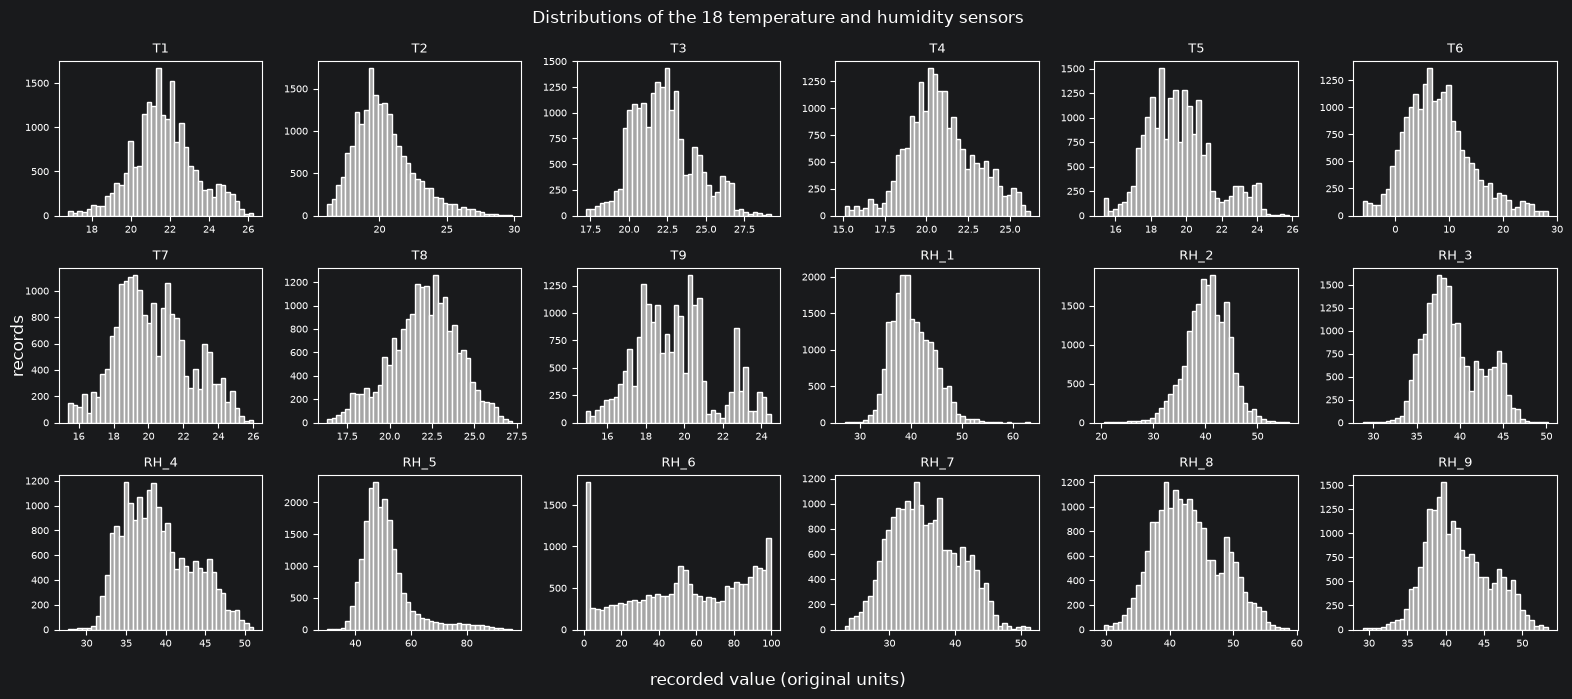

In [5]:
fig, ax = plt.subplots(3, 6, figsize=(16, 7)); ax = ax.ravel()
for a, v in zip(ax, Q_VARS):
    a.hist(abt[v], bins=40, color="0.65", edgecolor="white"); a.set_title(v, fontsize=9); a.tick_params(labelsize=7)
fig.supxlabel("recorded value (original units)"); fig.supylabel("records"); fig.suptitle("Distributions of the 18 temperature and humidity sensors")
plt.tight_layout(); plt.show()

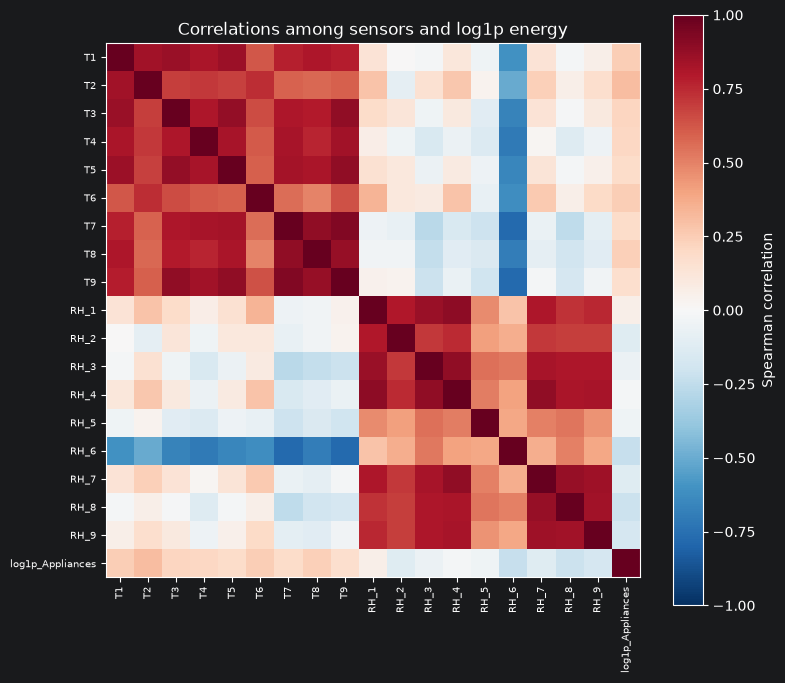

Spearman correlation with log1p_Appliances:


,rho
T2,0.305
T1,0.244
T6,0.242
T8,0.236
RH_6,-0.230
RH_8,-0.217


In [6]:
cols = Q_VARS + [LOG1P]
C = abt[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=7); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=7)
plt.colorbar(im, label="Spearman correlation"); ax.set_title("Correlations among sensors and log1p energy"); plt.tight_layout(); plt.show()
print("Spearman correlation with log1p_Appliances:"); display(C[LOG1P].drop(LOG1P).sort_values(key=abs, ascending=False).head(6).to_frame("rho"))

### Method: Variance Inflation Factor (diagnostic only)

- **Reference:** O'Brien, R. M. (2007). A caution regarding rules of thumb for variance inflation factors. *Quality & Quantity, 41*(5), 673–690. https://doi.org/10.1007/s11135-006-9018-6
- **Documentation:** none (computed here with NumPy least squares).
- **Purpose in this project:** shows how strongly each physical measurement is explained by the others. **VIF is never used to drop or merge rooms.** It only warns that group contributions in Q3 cannot be uniquely attributed to single rooms.

In [7]:
Xp = abt[manifest["groups"]["physical_measurements"]].to_numpy(float)
def vif(X):
    out = []
    for j in range(X.shape[1]):
        Z = np.c_[np.ones(len(X)), np.delete(X, j, 1)]; y = X[:, j]
        res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
        out.append(1 / (res.var() / y.var()))
    return pd.Series(out, index=manifest["groups"]["physical_measurements"], name="VIF")
VIF = vif(Xp).sort_values(ascending=False)
print(f"VIF (diagnostic only): {int((VIF > 10).sum())} of {len(VIF)} measurements exceed 10; nothing is dropped or merged.")
display(VIF.head(8).to_frame())

VIF (diagnostic only): 15 of 24 measurements exceed 10; nothing is dropped or merged.


,VIF
T_out,146.817
Tdewpoint,86.128
RH_out,49.207
T6,33.412
T2,28.638
T9,27.467
RH_2,21.821
T1,19.659


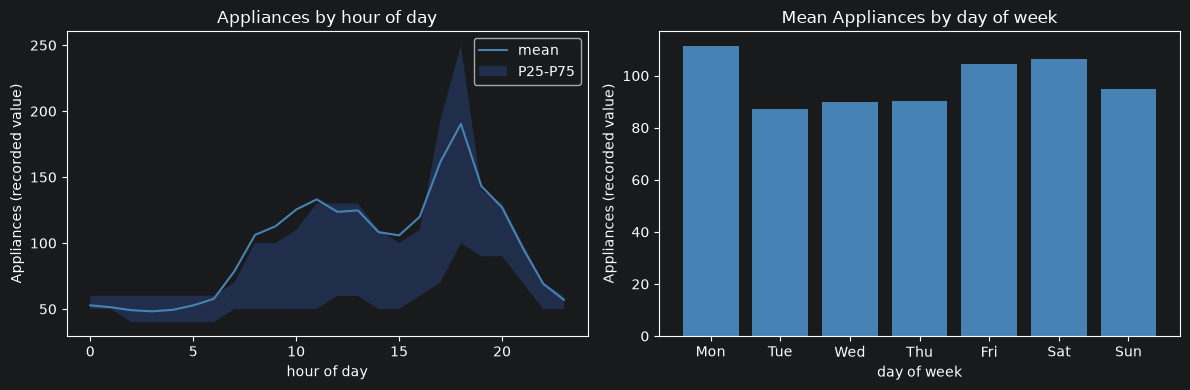

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h = abt.groupby("hour")[TARGET]; ax[0].plot(h.mean().index, h.mean(), color="steelblue", label="mean")
ax[0].fill_between(h.mean().index, h.quantile(.25), h.quantile(.75), alpha=.25, label="P25-P75"); ax[0].legend()
ax[0].set_title("Appliances by hour of day"); ax[0].set_xlabel("hour of day"); ax[0].set_ylabel("Appliances (recorded value)")
w = abt.groupby("dayofweek")[TARGET].mean(); ax[1].bar(w.index, w.values, color="steelblue")
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax[1].set_title("Mean Appliances by day of week"); ax[1].set_xlabel("day of week"); ax[1].set_ylabel("Appliances (recorded value)")
plt.tight_layout(); plt.show()

**the hourly and weekly profiles show when energy use is concentrated, which is the temporal signal Q3 will test against the environmental one.**

## 3 · Q1: Typical Ranges and Energy Response

Data: full dataset, original units, no scaling. **Typical = P25-P75; observed = min-max.** Bands: <P5, P5-25, P25-75, P75-95, ≥P95. For every band, mean `Appliances` relative to the typical band, with block-bootstrap confidence intervals (band edges fixed from the full data). A band can be empty when many records tie at a percentile (for example `RH_6`, whose lowest values repeat); it is reported as n/a.

### Method: Moving-Block Bootstrap

- **Reference:** Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241. https://doi.org/10.1214/aos/1176347265
- **Documentation:** https://numpy.org/doc/stable/reference/random/generator.html
- **Purpose in this project:** resamples whole 1-day blocks of consecutive records so autocorrelation is kept inside each block. It reduces, but does not remove, the effect of autocorrelation on the intervals.

In [9]:
E = abt[TARGET].to_numpy(float)
IDX_Q1 = block_idx(n, BLOCK, N_BOOT, rng)
BANDS = ["<P5", "P5-25", "P25-75", "P75-95", ">=P95"]
rows = []
for v in Q_VARS:
    x = abt[v].to_numpy(float); P = np.percentile(x, [5, 25, 75, 95])
    band = np.digitize(x, P)
    cnt = np.bincount(band, minlength=5)
    if (cnt == 0).any(): print(f"NOTE: {v} has an empty band {[BANDS[k] for k in range(5) if cnt[k] == 0]} (many records tie at that percentile); reported as n/a.")
    obs = np.array([E[band == k].mean() if cnt[k] else np.nan for k in range(5)])
    mb = np.empty((N_BOOT, 5))
    for s in range(0, N_BOOT, CHUNK):
        ib = IDX_Q1[s:s + CHUNK]; Eb, bb = E[ib], band[ib]
        with np.errstate(invalid="ignore", divide="ignore"):
            mb[s:s + CHUNK] = np.stack([(Eb * (bb == k)).sum(1) / (bb == k).sum(1) for k in range(5)], 1)
    ratio_b = mb / mb[:, [2]]
    for k in range(5):
        lo, hi = (np.percentile(ratio_b[:, k], [2.5, 97.5]) if cnt[k] else (np.nan, np.nan))
        rows.append(dict(variable=v, band=BANDS[k], n=int((band == k).sum()), mean_energy=obs[k], ratio_vs_typical=obs[k] / obs[2],
                         ci_lo=lo, ci_hi=hi, typical_lo=P[1], typical_hi=P[2], observed_min=x.min(), observed_max=x.max()))
Q1 = pd.DataFrame(rows)
print(f"{len(Q1)} band rows from {len(Q_VARS)} variables, {N_BOOT} block-bootstrap replicates")

NOTE: RH_6 has an empty band ['<P5'] (many records tie at that percentile); reported as n/a.
90 band rows from 18 variables, 1000 block-bootstrap replicates


In [10]:
rng_tbl = abt[Q_VARS].agg(["min", lambda s: s.quantile(.25), lambda s: s.quantile(.75), "max"]).T
rng_tbl.columns = ["observed_min", "typical_P25", "typical_P75", "observed_max"]
display(rng_tbl)

,observed_min,typical_P25,typical_P75,observed_max
T1,16.790,20.760,22.600,26.260
T2,16.100,18.790,21.500,29.857
T3,17.200,20.790,23.290,29.236
T4,15.100,19.530,22.100,26.200
T5,15.330,18.277,20.620,25.795
T6,-6.065,3.627,11.256,28.290
T7,15.390,18.700,21.600,26.000
T8,16.307,20.790,23.390,27.230
T9,14.890,18.000,20.600,24.500
RH_1,27.023,37.333,43.067,63.360


**typical ranges sit inside the observed ranges; the gap on each side is where the response bands below are measured.**

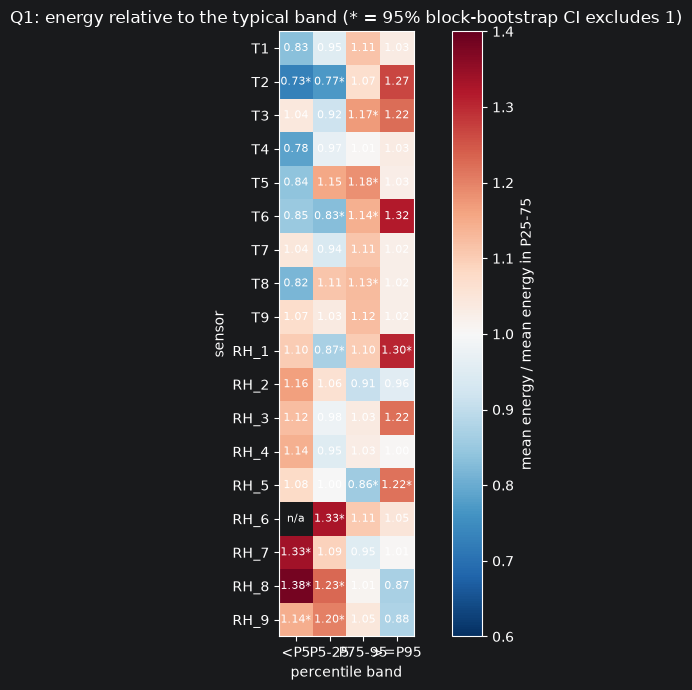

In [11]:
R = Q1.pivot(index="variable", columns="band", values="ratio_vs_typical").loc[Q_VARS, BANDS]
SIG = Q1.assign(sig=(Q1.ci_lo > 1) | (Q1.ci_hi < 1)).pivot(index="variable", columns="band", values="sig").loc[Q_VARS, BANDS]
fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(R.drop(columns="P25-75"), cmap="RdBu_r", vmin=0.6, vmax=1.4)
cols_ = [b for b in BANDS if b != "P25-75"]
for i, v in enumerate(Q_VARS):
    for j, b in enumerate(cols_):
        ax.text(j, i, ("n/a" if np.isnan(R.loc[v, b]) else f"{R.loc[v, b]:.2f}" + ("*" if SIG.loc[v, b] else "")), ha="center", va="center", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels(cols_); ax.set_yticks(range(len(Q_VARS))); ax.set_yticklabels(Q_VARS)
plt.colorbar(im, label="mean energy / mean energy in P25-75"); ax.set_xlabel("percentile band"); ax.set_ylabel("sensor")
ax.set_title("Q1: energy relative to the typical band (* = 95% block-bootstrap CI excludes 1)"); plt.tight_layout(); plt.show()

**values above 1 mean more energy than in the typical band; an asterisk marks bands whose interval excludes 1. This is an association, not a causal effect.**

## 4 · Q2: Thresholds

Threshold (hinge) regression of `log1p_Appliances` on each sensor, **both directions**: upper, `a + b·max(0, x − τ)` (flat below τ, rising above), and lower, `a + b·max(0, τ − x)` (flat above τ, rising below). The breakpoint τ is searched over the P10-P90 grid and **the search is repeated inside every bootstrap replicate**. Holm correction is applied across all tests of a run, and the model is repeated with hour-of-day controls.

**Why the first segment is flat.** With a free slope on both sides, the upper and lower models are algebraically the same line-with-a-kink, so they would give identical results and double-count one test. Fixing the pre-threshold slope at zero makes the two directions distinct and matches the question ("where does energy *begin* to increase"). A steady linear trend is fitted by a breakpoint at the search edge, which fails the interior-breakpoint criterion.

### Method: Threshold (Hinge) Regression with an Estimated Breakpoint

- **Reference:** Muggeo, V. M. R. (2003). Estimating regression models with unknown break-points. *Statistics in Medicine, 22*(19), 3055–3071. https://doi.org/10.1002/sim.1545 (regression with an unknown breakpoint; here the breakpoint is found by grid search instead of Muggeo's iterative linearisation, and the first segment is flat)
- **Documentation:** https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html
- **Purpose in this project:** finds the value of each sensor beyond which log energy changes slope, then asks whether that change is distinguishable from a straight line.

### Method: Block-Bootstrap Sup-F Test and Holm Correction

- **Reference:** Block bootstrap: Künsch (1989), cited in Section 3. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
- **Documentation:** https://numpy.org/doc/stable/reference/generated/numpy.argmax.html
- **Purpose in this project:** because τ is chosen from the data, an ordinary F-test is invalid. The p-value comes from resampling residual blocks of the constant-only fit (the null model), re-running the whole breakpoint search each time, and comparing the largest F. Breakpoint confidence intervals come from a separate block bootstrap of the data pairs. Holm controls the family-wise error across the 36 tests.

In [12]:
def hinge(xs, ts, direction):
    return np.maximum(0, xs[None, :] - ts[:, None]) if direction == "upper" else np.maximum(0, ts[:, None] - xs[None, :])

def fit_seg(xs, y, H, W):
    """Weighted OLS of y on [1, hinge_g] for every grid value g and every weight row of W (bootstrap counts)."""
    S0, Sy, Syy = W.sum(1), W @ y, W @ (y * y)
    Sh, Shh, Shy = W @ H.T, W @ (H * H).T, W @ (H * y).T
    det = S0[:, None] * Shh - Sh ** 2 + 1e-9
    a = (Shh * Sy[:, None] - Sh * Shy) / det; b = (S0[:, None] * Shy - Sh * Sy[:, None]) / det
    return np.stack([a, b], -1), Syy[:, None] - a * Sy[:, None] - b * Shy

def pick(beta, sse, dist, direction):
    g = sse.argmin(1); b = beta[np.arange(len(g)), g]
    return g, b, b[:, 1], np.expm1(b[:, 1] * dist[g]) * 100         # slope = energy change per SD moved away from typical

def null_supF(xs, y, H, IDX, Z=None):
    """Sup-F for the hinge term, observed and under the constant-only null (residual block bootstrap, search repeated)."""
    X0 = np.ones((len(xs), 1)) if Z is None else np.c_[np.ones(len(xs)), Z]
    Q = np.linalg.qr(X0)[0]; k = X0.shape[1]; nn = len(xs)
    r = y - Q @ (Q.T @ y); Ht = H - (H @ Q) @ Q.T; hh = (Ht * Ht).sum(1)
    def F(R):
        q = (R @ Ht.T) ** 2 / hh; rr = (R * R).sum(1)[:, None]
        return q / ((rr - q) / (nn - k - 1))
    Fo = F(r[None, :])[0]; sup = []
    for s in range(0, len(IDX), CHUNK):
        Es = r[IDX[s:s + CHUNK]]; sup.append(F(Es - (Es @ Q) @ Q.T).max(1))
    sup = np.concatenate(sup)
    return Fo.max(), int(Fo.argmax()), (1 + (sup >= Fo.max()).sum()) / (len(sup) + 1)

In [13]:
def seg_test(x, y, direction, IDX_P, IDX_N, Z=None, ci=True):
    nn = len(x); mu, sd = x.mean(), x.std(); xs = (x - mu) / sd
    grid = np.quantile(x, np.linspace(GRID_LO, GRID_HI, GRID_N)); ts = (grid - mu) / sd
    p5, p95 = np.percentile(xs, [5, 95]); dist = (p95 - ts) if direction == "upper" else (ts - p5)
    H = hinge(xs, ts, direction)
    beta, sse = fit_seg(xs, y, H, np.ones((1, nn)))
    g, b, slope, pct = pick(beta, sse, dist, direction)
    out = dict(tau_hat=grid[g[0]], interior=bool(0 < g[0] < GRID_N - 1), slope_after_per_sd=slope[0], pct_to_extreme=pct[0],
               a=b[0, 0], b2=b[0, 1], mu=mu, sd=sd)
    if ci:
        taus, edge = [], []
        for s in range(0, len(IDX_P), CHUNK):
            ip = IDX_P[s:s + CHUNK]; W = np.zeros((len(ip), nn))
            for i in range(len(ip)): W[i] = np.bincount(ip[i], minlength=nn)
            bb, ss = fit_seg(xs, y, H, W); gb = ss.argmin(1); taus.append(grid[gb]); edge.append((gb == 0) | (gb == GRID_N - 1))
        taus, edge = np.concatenate(taus), np.concatenate(edge)
        out.update(tau_lo=np.percentile(taus, 2.5), tau_hi=np.percentile(taus, 97.5), edge_share=edge.mean())
        out["supF"], _, out["p_raw"] = null_supF(xs, y, H, IDX_N)
    else:
        _, gh, out["p_hour_raw"] = null_supF(xs, y, H, IDX_N, Z=Z); out["tau_hat_hour"] = grid[gh]
    return out

HOUR_Z = pd.get_dummies(abt["hour"], drop_first=True).to_numpy(float)

def q2_run(y_all, tag, variables=Q_VARS, mask=None, hour=True):
    t0 = time.perf_counter(); sel = np.ones(n, bool) if mask is None else mask
    y = y_all[sel]; nn = int(sel.sum())
    IDX_P, IDX_N = block_idx(nn, BLOCK, N_BOOT, rng), block_idx(nn, BLOCK, N_BOOT, rng)
    rows = []
    for v in variables:
        x = abt[v].to_numpy(float)[sel]
        for d in ("upper", "lower"):
            r = dict(variable=v, direction=d, run=tag, n_rows=nn, **seg_test(x, y, d, IDX_P, IDX_N))
            if hour: r.update(seg_test(x, y, d, IDX_P, IDX_N, Z=HOUR_Z[sel], ci=False))
            rows.append(r)
    D = pd.DataFrame(rows); D["p_holm"] = holm(D["p_raw"])
    if hour: D["p_hour_holm"] = holm(D["p_hour_raw"])
    D["c1_holm"] = D.p_holm < ALPHA; D["c2_interior"] = D.interior; D["c3_slope_pos"] = D.slope_after_per_sd > 0
    for f in FLOORS: D[f"c4_pct{f}"] = D.pct_to_extreme >= f
    D["supported_c1to4_10"] = D.c1_holm & D.c2_interior & D.c3_slope_pos & D.c4_pct10
    D["c5_hour"] = (D.p_hour_holm < ALPHA) if hour else np.nan
    for f in FLOORS:
        base = D.c1_holm & D.c2_interior & D.c3_slope_pos & D[f"c4_pct{f}"]
        D[f"supported_{f}"] = base & D.c5_hour if hour else base
    print(f"[{tag}] {len(D)} tests, n={nn:,}, {time.perf_counter() - t0:.0f} s | min attainable Holm p = {len(D) / (N_BOOT + 1):.4f}")
    return D

In [14]:
Q2_MAIN = q2_run(abt[LOG1P].to_numpy(float), "main")
print("Supported thresholds (10% floor):", int(Q2_MAIN.supported_10.sum()), "of", len(Q2_MAIN))
print(f"Tests whose raw p sits at the bootstrap floor (1/{N_BOOT + 1}): {int((Q2_MAIN.p_raw <= 1 / (N_BOOT + 1) + 1e-12).sum())} of {len(Q2_MAIN)}; they tie on Holm p, so sup-F is used to rank them.")

[main] 36 tests, n=19,735, 49 s | min attainable Holm p = 0.0360
Supported thresholds (10% floor): 0 of 36
Tests whose raw p sits at the bootstrap floor (1/1001): 22 of 36; they tie on Holm p, so sup-F is used to rank them.


**the support flag requires all five criteria together, so a significant p-value alone does not make a threshold 'supported'. With this many records most tests reach the smallest p the bootstrap can give, so criteria 2-5 do the real filtering.**

In [15]:
cols_show = ["variable", "direction", "tau_hat", "tau_lo", "tau_hi", "supF", "p_holm", "p_hour_holm", "slope_after_per_sd", "pct_to_extreme",
             "c1_holm", "c2_interior", "c3_slope_pos", "c4_pct10", "c5_hour", "supported_10"]
display(Q2_MAIN.sort_values(["p_holm", "supF"], ascending=[True, False])[cols_show].head(12))

,variable,direction,tau_hat,tau_lo,tau_hi,supF,p_holm,p_hour_holm,slope_after_per_sd,pct_to_extreme,c1_holm,c2_interior,c3_slope_pos,c4_pct10,c5_hour,supported_10
3,T2,lower,21.100,20.000,22.434,"1,158.216",0.036,0.036,-0.258,-35.920,True,True,False,False,True,False
2,T2,upper,17.890,17.890,17.890,923.037,0.036,0.184,0.143,54.423,True,False,True,True,False,False
29,RH_6,lower,51.327,19.800,61.463,866.560,0.036,1.000,0.237,46.764,True,True,True,True,False,False
11,T6,lower,16.058,6.157,16.058,776.258,0.036,1.000,-0.147,-33.255,True,False,False,False,False,False
10,T6,upper,0.833,0.833,1.260,759.498,0.036,1.000,0.132,50.111,True,False,True,True,False,False
33,RH_8,lower,43.483,40.253,50.374,640.216,0.036,1.000,0.204,37.775,True,True,True,True,False,False
28,RH_6,upper,5.291,5.291,5.291,591.049,0.036,1.000,-0.113,-28.696,True,False,False,False,False,False
1,T1,lower,22.890,22.200,23.963,573.503,0.036,0.036,-0.139,-28.017,True,True,False,False,True,False
4,T3,upper,19.924,19.924,20.508,562.267,0.036,0.036,0.114,43.047,True,False,True,True,True,False
5,T3,lower,25.100,21.730,25.100,529.248,0.036,0.036,-0.118,-28.031,True,False,False,False,True,False


### Sensitivity runs (side by side)

- **S1:** `RH_6` thresholds without records where `RH_6 < 10` (flag from NB1). Rows are removed first and the series is then resampled in blocks of the remaining records, so a block can bridge a removed stretch (an approximation).
- **S2:** all thresholds with the energy target capped at P99 (`log1p_Appliances_p99cap`).
- Neither sensitivity run repeats the hour-control test, so the side-by-side tables compare the **criteria 1-4** flag (`supported_c1to4_10`) for all runs. The headline `supported_10` flag (which adds the hour-control criterion) is reported for the main run only.

In [16]:
Q2_S1 = q2_run(abt[LOG1P].to_numpy(float), "S1_RH6_no_low", variables=["RH_6"], mask=~abt["flag_rh6_below_10"].to_numpy(), hour=False)
Q2_S2 = q2_run(abt[LOG1P_CAP].to_numpy(float), "S2_capped_P99", hour=False)

[S1_RH6_no_low] 2 tests, n=17,307, 2 s | min attainable Holm p = 0.0020
[S2_capped_P99] 36 tests, n=19,735, 44 s | min attainable Holm p = 0.0360


In [17]:
keys = ["variable", "direction"]
side = Q2_MAIN[keys + ["tau_hat", "p_holm", "pct_to_extreme", "supported_c1to4_10"]].merge(
    Q2_S2[keys + ["tau_hat", "p_holm", "pct_to_extreme", "supported_c1to4_10"]], on=keys, suffixes=("_main", "_capped"))
side = side.merge(Q2_S1[keys + ["tau_hat", "p_holm", "pct_to_extreme", "supported_c1to4_10"]].add_suffix("_RH6filtered").rename(
    columns={"variable_RH6filtered": "variable", "direction_RH6filtered": "direction"}), on=keys, how="left")
display(side[(side.supported_c1to4_10_main) | (side.supported_c1to4_10_capped) | (side.variable == "RH_6")])
print("Supported under floor of 5% / 10% / 20%:", [int(Q2_MAIN[f"supported_{f}"].sum()) for f in FLOORS])

,variable,direction,tau_hat_main,p_holm_main,pct_to_extreme_main,supported_c1to4_10_main,tau_hat_capped,p_holm_capped,pct_to_extreme_capped,supported_c1to4_10_capped,tau_hat_RH6filtered,p_holm_RH6filtered,pct_to_extreme_RH6filtered,supported_c1to4_10_RH6filtered
18,RH_1,upper,39.290,0.036,19.612,True,39.290,0.044,19.436,True,NaN,NaN,NaN,NaN
21,RH_2,lower,41.500,0.036,21.539,True,41.500,0.036,21.482,True,NaN,NaN,NaN,NaN
28,RH_6,upper,5.291,0.036,-28.696,False,5.291,0.036,-28.671,False,24.459,0.011,-16.182,False
29,RH_6,lower,51.327,0.036,46.764,True,51.327,0.036,46.624,True,52.372,0.002,28.186,True
31,RH_7,lower,32.500,0.036,24.498,True,32.500,0.036,24.445,True,NaN,NaN,NaN,NaN
33,RH_8,lower,43.483,0.036,37.775,True,43.483,0.036,37.697,True,NaN,NaN,NaN,NaN
35,RH_9,lower,39.967,0.036,24.984,True,39.967,0.036,25.020,True,NaN,NaN,NaN,NaN


Supported under floor of 5% / 10% / 20%: [0, 0, 0]


**the side-by-side table shows whether a threshold survives the P99 cap and (for RH_6) the removal of very low readings; thresholds that appear in only one column are fragile.**

### Crossing frequency (supported thresholds only)

Elevated side: `x > τ` (upper) or `x < τ` (lower). Counted over the **19,734 consecutive 10-minute transitions**. Ranked by crossings. **Crossing frequency says how often a threshold is crossed; it is not an effect size.**

In [18]:
SUP = Q2_MAIN[Q2_MAIN.supported_10]
days = N_TRANS * 10 / 1440
cr = []
for _, r in SUP.iterrows():
    x = abt[r.variable].to_numpy(float); s = (x > r.tau_hat) if r.direction == "upper" else (x < r.tau_hat)
    into, out_ = int((~s[:-1] & s[1:]).sum()), int((s[:-1] & ~s[1:]).sum())
    cr.append(dict(variable=r.variable, direction=r.direction, tau_hat=r.tau_hat, crossings_into_elevated=into, crossings_out=out_,
                   crossings_total=into + out_, per_1000_transitions=(into + out_) / N_TRANS * 1000, per_day=(into + out_) / days,
                   pct_time_elevated=s.mean() * 100))
CROSS = pd.DataFrame(cr).sort_values("crossings_total", ascending=False) if cr else pd.DataFrame(
    columns=["variable", "direction", "tau_hat", "crossings_into_elevated", "crossings_out", "crossings_total", "per_1000_transitions", "per_day", "pct_time_elevated"])
print(f"Crossing frequency: {len(CROSS)} supported threshold(s); denominator = {N_TRANS:,} transitions, {days:.1f} days")
display(CROSS) if len(CROSS) else print("No threshold met all five support criteria, so no crossing frequencies are reported.")

Crossing frequency: 0 supported threshold(s); denominator = 19,734 transitions, 137.0 days
No threshold met all five support criteria, so no crossing frequencies are reported.


**the ranking orders rooms by how often they move across a supported threshold; a frequently crossed threshold is not necessarily one with a large energy effect.**

In [19]:
N_BOOT_V2 = 5000      # replicates; each is generated in chunks so memory stays small. Expect a few minutes.

def _F(R, Ht, hh, nn, k):
    q = (R @ Ht.T) ** 2 / hh; rr = (R * R).sum(1)[:, None]
    return q / ((rr - q) / (nn - k - 1))

def seg_test_v2(x, y, direction, seed_key, Zhour):
    nn = len(x); mu, sd = x.mean(), x.std(); xs = (x - mu) / sd
    grid = np.quantile(x, np.linspace(GRID_LO, GRID_HI, GRID_N)); ts = (grid - mu) / sd
    p5, p95 = np.percentile(xs, [5, 95]); dist = (p95 - ts) if direction == "upper" else (ts - p5)
    H = hinge(xs, ts, direction)
    X0 = np.c_[np.ones(nn), xs, Zhour]; Q = np.linalg.qr(X0)[0]; k = X0.shape[1]      # null: straight line + hour of day
    r = y - Q @ (Q.T @ y); Ht = H - (H @ Q) @ Q.T; hh = (Ht * Ht).sum(1)              # residualise on the controls (FWL)
    beta, sse = fit_seg(xs, r, Ht, np.ones((1, nn))); g, b, slope, pct = pick(beta, sse, dist, direction)
    Fo = _F(r[None, :], Ht, hh, nn, k)[0]
    rng_v = np.random.default_rng(seed_key); sup, taus, edge = [], [], []
    for s in range(0, N_BOOT_V2, CHUNK):
        B = min(CHUNK, N_BOOT_V2 - s)
        ip = block_idx(nn, BLOCK, B, rng_v); W = np.zeros((B, nn))
        for i in range(B): W[i] = np.bincount(ip[i], minlength=nn)
        _, ss = fit_seg(xs, r, Ht, W); gb = ss.argmin(1)                                # breakpoint CI: resample (r, Ht) blocks
        taus.append(grid[gb]); edge.append((gb == 0) | (gb == GRID_N - 1))
        Es = r[block_idx(nn, BLOCK, B, rng_v)]; Es = Es - (Es @ Q) @ Q.T                # null: resampled residuals, search repeated
        sup.append(_F(Es, Ht, hh, nn, k).max(1))
    sup = np.concatenate(sup); taus = np.concatenate(taus); edge = np.concatenate(edge)
    out = dict(tau_hat=grid[g[0]], interior=bool(0 < g[0] < GRID_N - 1), kink_slope_per_sd=slope[0], pct_beyond_trend=pct[0],
               supF=Fo.max(), p_raw=(1 + (sup >= Fo.max()).sum()) / (len(sup) + 1),
               tau_lo=np.percentile(taus, 2.5), tau_hi=np.percentile(taus, 97.5), edge_share=edge.mean(),
               ci_width_frac=(np.percentile(taus, 97.5) - np.percentile(taus, 2.5)) / (grid[-1] - grid[0]))
    return out, sup, (r, Ht, hh, nn, k, dist)

def q2_run_v2(y_all, tag, variables=Q_VARS):
    t0 = time.perf_counter(); rows, SUP, CTX = [], {}, {}
    for vi, v in enumerate(variables):
        x = abt[v].to_numpy(float)
        for di, d in enumerate(("upper", "lower")):
            o, sup, ctx = seg_test_v2(x, y_all, d, [SEED, vi, di], HOUR_Z)
            rows.append(dict(variable=v, direction=d, run=tag, **o)); SUP[(v, d)] = sup; CTX[(v, d)] = ctx
    D = pd.DataFrame(rows); nt = len(D); D["p_holm"] = holm(D.p_raw)
    g0 = GRID_N // 2; mde = []                                                         # detectable kink at the median breakpoint
    for (v, d) in zip(D.variable, D.direction):
        crit = np.quantile(SUP[(v, d)], 1 - ALPHA / nt); r, Ht, hh, nn, k, dist = CTX[(v, d)]
        mde.append(next((p for p in range(1, 101) if _F((r + np.log1p(p / 100) / dist[g0] * Ht[g0])[None, :], Ht, hh, nn, k).max() >= crit), np.nan))
    D["detectable_pct_at_extreme"] = mde
    D["c1_holm"] = D.p_holm < ALPHA; D["c2_interior"] = D.interior; D["c3_slope_pos"] = D.kink_slope_per_sd > 0
    D["c4_pct10"] = D.pct_beyond_trend >= 10
    D["supported"] = D.c1_holm & D.c2_interior & D.c3_slope_pos & D.c4_pct10
    D["stable_interval"] = (D.ci_width_frac <= 0.5) & (D.edge_share <= 0.2)
    print(f"[{tag}] {nt} tests, {N_BOOT_V2} replicates, {time.perf_counter() - t0:.0f} s | min attainable Holm p = {nt / (N_BOOT_V2 + 1):.4f}")
    return D

Y_LOG = abt[LOG1P].to_numpy(float)

Q2V2 = q2_run_v2(Y_LOG, "main_v2")
display(Q2V2[["variable", "direction", "tau_hat", "tau_lo", "tau_hi", "ci_width_frac", "edge_share", "pct_beyond_trend",
              "p_raw", "p_holm", "supported", "stable_interval", "detectable_pct_at_extreme"]].round(4))
ns = int(Q2V2.supported.sum())
print(f"Supported thresholds (kink beyond straight line, hour controlled, Holm p<0.05, interior, +slope, >=10%): {ns} of {len(Q2V2)}")
print(f"Median detectable effect: a kink that changes appliance energy by ~{Q2V2.detectable_pct_at_extreme.median():.0f}% "
      f"(range {Q2V2.detectable_pct_at_extreme.min():.0f}-{Q2V2.detectable_pct_at_extreme.max():.0f}%) between a mid-range breakpoint and the P95/P5 extreme "
      "would just have been flagged at the Holm level. Smaller kinks than that cannot be ruled out.")

[main_v2] 36 tests, 5000 replicates, 170 s | min attainable Holm p = 0.0072


,variable,direction,tau_hat,tau_lo,tau_hi,ci_width_frac,edge_share,pct_beyond_trend,p_raw,p_holm,supported,stable_interval,detectable_pct_at_extreme
0,T1,upper,22.500,20.000,23.963,0.930,0.092,-20.941,0.014,0.417,False,False,91.000
1,T1,lower,22.500,20.000,23.963,0.930,0.097,-30.151,0.010,0.326,False,False,68.000
2,T2,upper,20.857,19.427,22.434,0.553,0.006,-27.121,0.001,0.043,False,False,NaN
3,T2,lower,20.857,19.323,22.434,0.572,0.007,-26.069,0.002,0.077,False,False,61.000
4,T3,upper,21.000,19.924,25.100,1.000,0.233,-20.785,0.512,1.000,False,False,64.000
5,T3,lower,21.000,19.924,25.100,1.000,0.228,-6.500,0.507,1.000,False,False,38.000
6,T4,upper,21.239,18.500,23.790,1.000,0.092,-22.403,0.020,0.551,False,False,92.000
7,T4,lower,21.239,18.500,23.790,1.000,0.093,-23.524,0.018,0.515,False,False,62.000
8,T5,upper,22.480,17.500,22.480,1.000,0.373,-13.098,0.062,1.000,False,False,NaN
9,T5,lower,22.480,17.500,22.480,1.000,0.383,-56.404,0.062,1.000,False,False,51.000


Supported thresholds (kink beyond straight line, hour controlled, Holm p<0.05, interior, +slope, >=10%): 0 of 36
Median detectable effect: a kink that changes appliance energy by ~56% (range 15-92%) between a mid-range breakpoint and the P95/P5 extreme would just have been flagged at the Holm level. Smaller kinks than that cannot be ruled out.


## 5 · Q3: Variance Explained

**Validation.** Outer: 5 contiguous time blocks with a 1-day buffer on each side (R² is reported **only** on these blocks). Inner: hyperparameters tuned on the training blocks only, with the same time-blocked structure (3 contiguous blocks, 1-day buffer). The outer blocks are identical for every group and model.

**Models.** GBM (scikit-learn `HistGradientBoostingRegressor`), RF, XGB (skipped with a warning if `xgboost` is not installed) and SVR (feature scaler fitted on training blocks only, SVR only). Hour (24) and day of week (7) are one-hot encoded inside each pipeline.

**Groups.** temporal, indoor, outdoor, indoor + outdoor (environment), all combined, `rv1`, and the 20 random columns. **Meaning: incremental predictive value, not causal or uniquely attributable variance.**

### Method: Time-Blocked Nested Cross-Validation with a Buffer

- **Reference:** Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881
- **Documentation:** https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- **Purpose in this project:** the paper supports blocked (not random) cross-validation when observations are dependent. Random folds would leak neighbouring 10-minute records between training and test, so contiguous blocks are used and tuning happens only inside the training blocks. **The 1-day buffer length and the block counts are project choices**, not taken from the paper.

### Method: GBM, Random Forest, XGBoost and Support Vector Regression

- **Reference:** Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451; Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324; Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). https://doi.org/10.1145/2939672.2939785; Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing, 14*(3), 199–222. https://doi.org/10.1023/B:STCO.0000035301.49549.88; Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- **Documentation:** https://scikit-learn.org/stable/modules/ensemble.html
- **Purpose in this project:** four different model families, so a conclusion about temporal vs environmental value does not depend on one algorithm. Hyperparameter grids are deliberately small (2 values per model). SVR trains on every 8th training record because kernel SVR is O(n²).

In [20]:
Y_LOG = abt[LOG1P].to_numpy(float); Y_CAP = abt[LOG1P_CAP].to_numpy(float)
GROUPS_Q3 = {"temporal": ag["temporal"], "indoor": ag["indoor"], "outdoor": ag["outdoor"], "indoor_outdoor": ag["indoor_outdoor"],
             "combined": ag["temporal_indoor_outdoor"], "rv1": ag["negative_control_rv1"], "random_20": ag["negative_control_random"]}
CAT = ["hour", "dayofweek"]

def blocks(pos, K, buf):
    pos = np.asarray(pos); out = []
    for p in np.array_split(pos, K):
        lo, hi = p.min(), p.max(); out.append((pos[(pos < lo - buf) | (pos > hi + buf)], p))
    return out

MODELS = {
    "GBM": (HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, random_state=SEED), {"model__learning_rate": [0.05, 0.1]}),
    "RF":  (RandomForestRegressor(n_estimators=80, max_features=0.5, max_samples=0.5, n_jobs=-1, random_state=SEED), {"model__min_samples_leaf": [10, 40]}),
    "SVR": (SVR(kernel="rbf", epsilon=0.1), {"model__C": [1, 10]}),
}
if XGBRegressor is not None:
    MODELS["XGB"] = (XGBRegressor(n_estimators=150, learning_rate=0.1, subsample=0.8, tree_method="hist", n_jobs=-1, random_state=SEED), {"model__max_depth": [3, 6]})
else:
    print("WARNING: xgboost is not installed; XGB is skipped. Install it (pip install xgboost) and rerun to include it.")

def make_pipe(mname, cols):
    cat = [c for c in cols if c in CAT]; num = [c for c in cols if c not in CAT]
    ct = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                            ("num", StandardScaler() if mname == "SVR" else "passthrough", num)])
    return Pipeline([("prep", ct), ("model", MODELS[mname][0])])

OUTER = blocks(np.arange(n), N_OUTER, BUFFER)
print("Outer test blocks (record positions):", [(int(te.min()), int(te.max())) for _, te in OUTER])
print("Training rows per outer fold:", [len(tr) for tr, _ in OUTER])

Outer test blocks (record positions): [(0, 3946), (3947, 7893), (7894, 11840), (11841, 15787), (15788, 19734)]
Training rows per outer fold: [15644, 15500, 15500, 15500, 15644]


In [21]:
import hashlib
CACHE = OUT / "q3_fold_results.csv"
META = OUT / "q3_fold_results.meta.json"
COLS_Q3 = ["run", "group", "model", "fold", "r2", "best"]

# Fingerprint of everything that would change the Q3 numbers: settings, group definitions, model grids, and the ABT itself.
SETTINGS_Q3 = dict(seed=SEED, n_outer=N_OUTER, n_inner=N_INNER, buffer=BUFFER, svr_thin=SVR_THIN,
                   groups={g: list(c) for g, c in GROUPS_Q3.items()},
                   models={m: [repr(MODELS[m][0]), {k: list(v) for k, v in MODELS[m][1].items()}] for m in MODELS},
                   abt_shape=list(abt.shape), abt_hash=hashlib.sha256(
                       pd.util.hash_pandas_object(abt[[LOG1P, LOG1P_CAP] + sorted({c for cs in GROUPS_Q3.values() for c in cs})], index=False).to_numpy().tobytes()).hexdigest())
FINGERPRINT = hashlib.sha256(json.dumps(SETTINGS_Q3, sort_keys=True).encode()).hexdigest()

def _cache_matches():
    try: return json.loads(META.read_text()).get("fingerprint") == FINGERPRINT
    except Exception: return False

if RECOMPUTE_Q3:
    DONE = pd.DataFrame(columns=COLS_Q3); print("Q3 cache: computed fresh (RECOMPUTE_Q3=True).")
elif CACHE.exists() and _cache_matches():
    DONE = pd.read_csv(CACHE); print(f"Q3 cache: loaded, settings match (fingerprint {FINGERPRINT[:10]}, {len(DONE)} rows).")
else:
    DONE = pd.DataFrame(columns=COLS_Q3)
    print("Q3 cache: " + ("settings changed or no metadata; old cache ignored, " if CACHE.exists() else "none found; ") + "computed fresh.")

def run_q3(y, groups, tag):
    """Fits every model for each group on the identical outer blocks; saves after each group so the run can resume."""
    global DONE
    for g, cols in groups.items():
        have = DONE[(DONE.run == tag) & (DONE.group == g)]
        if set(MODELS) <= set(have.model):
            print(f"  [{tag}] {g}: loaded from cache"); continue
        DONE = DONE.drop(have.index); t0 = time.perf_counter(); res = []
        for m in MODELS:
            for k, (tr, te) in enumerate(OUTER):
                trm = tr[::SVR_THIN] if m == "SVR" else tr
                cv = [(np.searchsorted(trm, a), np.searchsorted(trm, b)) for a, b in blocks(trm, N_INNER, BUFFER)]
                gs = GridSearchCV(make_pipe(m, cols), MODELS[m][1], cv=cv, scoring="r2", refit=True)
                gs.fit(abt.iloc[trm][cols], y[trm])
                res.append(dict(run=tag, group=g, model=m, fold=k, r2=r2_score(y[te], gs.predict(abt.iloc[te][cols])), best=str(gs.best_params_)))
        DONE = pd.concat([DONE, pd.DataFrame(res)], ignore_index=True); DONE.to_csv(CACHE, index=False)
        META.write_text(json.dumps(dict(fingerprint=FINGERPRINT, settings=SETTINGS_Q3), indent=1))
        print(f"  [{tag}] {g} done ({time.perf_counter() - t0:.0f} s)")

Q3 cache: settings changed or no metadata; old cache ignored, computed fresh.


In [22]:
run_q3(Y_LOG, GROUPS_Q3, "main")
run_q3(Y_CAP, {k: GROUPS_Q3[k] for k in ("temporal", "indoor_outdoor", "combined")}, "capped_P99")
Q3 = DONE.copy()
print(f"Q3 fold results: {len(Q3)} rows | models: {sorted(Q3.model.unique())}")

  [main] temporal done (51 s)
  [main] indoor done (122 s)
  [main] outdoor done (106 s)
  [main] indoor_outdoor done (190 s)
  [main] combined done (241 s)
  [main] rv1 done (95 s)
  [main] random_20 done (84 s)
  [capped_P99] temporal done (130 s)
  [capped_P99] indoor_outdoor done (182 s)
  [capped_P99] combined done (111 s)
Q3 fold results: 200 rows | models: ['GBM', 'RF', 'SVR', 'XGB']


In [23]:
M = Q3[Q3.run == "main"]
R2T = M.groupby(["model", "group"]).r2.agg(mean_r2="mean", min_r2="min", max_r2="max").reset_index()
display(R2T.pivot(index="model", columns="group", values="mean_r2")[list(GROUPS_Q3)])

group,temporal,indoor,outdoor,indoor_outdoor,combined,rv1,random_20
model,,,,,,,
GBM,0.243,-0.203,-0.128,-0.115,-0.003,-0.011,-0.012
RF,0.248,-0.012,0.001,-0.042,0.042,-0.020,-0.015
SVR,0.147,0.053,-0.020,0.138,0.217,-0.084,-0.138
XGB,0.246,-0.458,-0.174,-0.432,-0.004,-0.014,-0.026


**mean out-of-sample R² per model and group, on the log1p scale; the `rv1` and `random_20` columns are the null reference.**

In [24]:
def per_fold(df, m):
    W = df[df.model == m].pivot(index="fold", columns="group", values="r2"); return W
rows = []
for run, d in Q3.groupby("run"):
    for m in sorted(d.model.unique()):
        W = per_fold(d, m); T, EN, C = W["temporal"], W["indoor_outdoor"], W["combined"]
        for name, s in {"combined - temporal": C - T, "combined - environment": C - EN,
                        "unique to temporal": C - EN, "unique to environment": C - T, "shared": T + EN - C}.items():
            rows.append(dict(run=run, model=m, quantity=name, mean=s.mean(), min=s.min(), max=s.max(), n_folds_positive=int((s > 0).sum())))
INC = pd.DataFrame(rows)
display(INC[INC.run == "main"].drop(columns="run"))

,model,quantity,mean,min,max,n_folds_positive
20,GBM,combined - temporal,-0.246,-1.094,0.011,1
21,GBM,combined - environment,0.112,-0.168,0.381,4
22,GBM,unique to temporal,0.112,-0.168,0.381,4
23,GBM,unique to environment,-0.246,-1.094,0.011,1
24,GBM,shared,0.131,-0.244,0.416,4
25,RF,combined - temporal,-0.207,-0.732,-0.045,0
26,RF,combined - environment,0.084,0.050,0.146,5
27,RF,unique to temporal,0.084,0.050,0.146,5
28,RF,unique to environment,-0.207,-0.732,-0.045,0
29,RF,shared,0.164,0.079,0.226,5


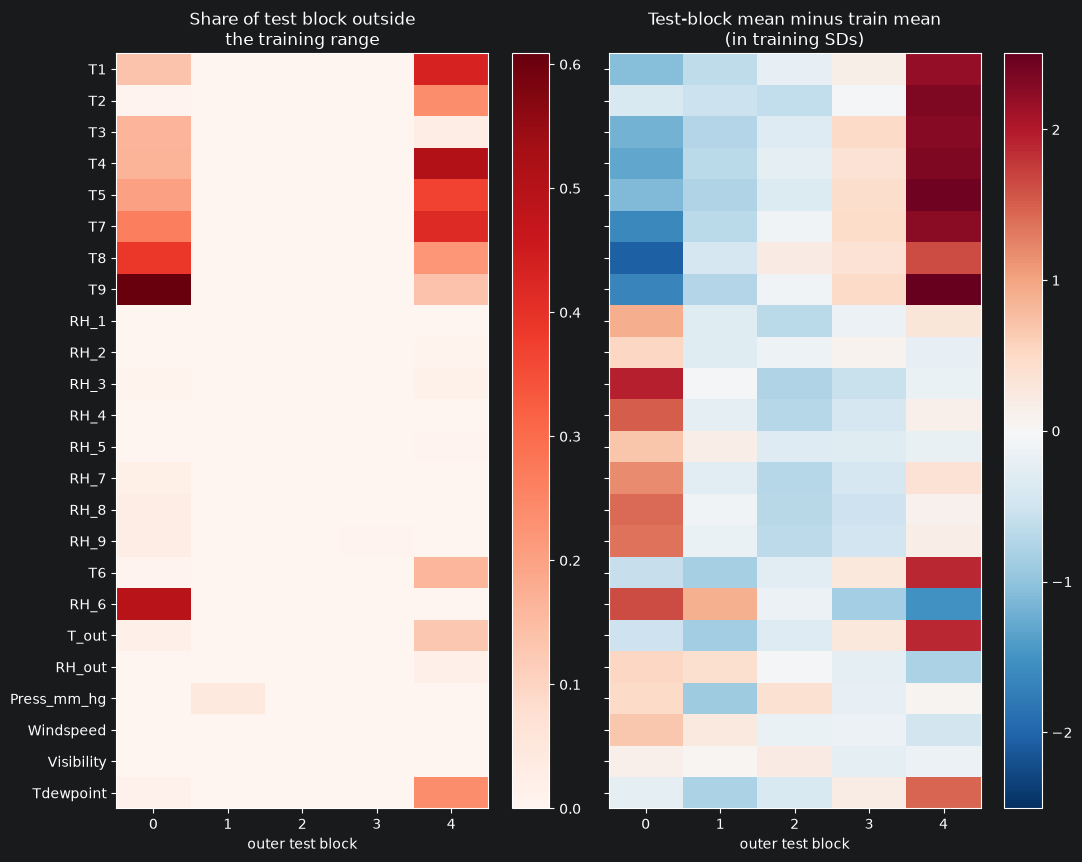

Mean share of test rows outside the training range, by block:
 fold
0   0.106
1   0.002
2   0.000
3   0.000
4   0.122
Mean |shift| in training SDs, by block:
 fold
0   1.030
1   0.490
2   0.360
3   0.330
4   1.160


In [25]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import make_pipeline

SENS = GROUPS_Q3["indoor_outdoor"]
rows = []
for k, (tr, te) in enumerate(OUTER):
    for s in SENS:
        a = abt[s].to_numpy(float); lo, hi = a[tr].min(), a[tr].max()
        rows.append(dict(fold=k, sensor=s,
                         share_outside=float(((a[te] < lo) | (a[te] > hi)).mean()),
                         shift_in_train_sd=(a[te].mean() - a[tr].mean()) / a[tr].std()))
RANGE = pd.DataFrame(rows)
P1 = RANGE.pivot(index="sensor", columns="fold", values="share_outside").loc[SENS]
P2 = RANGE.pivot(index="sensor", columns="fold", values="shift_in_train_sd").loc[SENS]

fig, ax = plt.subplots(1, 2, figsize=(11, 0.28 * len(SENS) + 2), sharey=True)
im0 = ax[0].imshow(P1.values, aspect="auto", cmap="Reds", vmin=0, vmax=max(0.5, P1.values.max()))
ax[0].set_title("Share of test block outside\nthe training range"); plt.colorbar(im0, ax=ax[0])
lim = np.abs(P2.values).max()
im1 = ax[1].imshow(P2.values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[1].set_title("Test-block mean minus train mean\n(in training SDs)"); plt.colorbar(im1, ax=ax[1])
for a_ in ax:
    a_.set_xticks(range(N_OUTER)); a_.set_xlabel("outer test block")
ax[0].set_yticks(range(len(SENS))); ax[0].set_yticklabels(SENS)
plt.tight_layout(); plt.show()
print("Mean share of test rows outside the training range, by block:\n", P1.mean().round(3).to_string())
print("Mean |shift| in training SDs, by block:\n", P2.abs().mean().round(2).to_string())


In [26]:
abtd = abt.copy(); DES = []
for s in SENS:                                           # deviation from the sensor's own trailing 1-day mean (uses only the past)
    abtd[s + "_dev"] = abt[s] - abt[s].rolling(144, min_periods=1).mean(); DES.append(s + "_dev")

def eval_group(name, cols, kind, df=abtd):
    out = []
    for k, (tr, te) in enumerate(OUTER):
        if kind == "hour_mean":
            mu = pd.Series(Y_LOG[tr]).groupby(df["hour"].to_numpy()[tr]).mean()
            pred = df["hour"].iloc[te].map(mu).to_numpy()
        else:
            cv = [(np.searchsorted(tr, a), np.searchsorted(tr, b)) for a, b in blocks(tr, N_INNER, BUFFER)]
            if kind == "ridge":
                cat = [c for c in cols if c in CAT]; num = [c for c in cols if c not in CAT]
                pipe = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                                                             ("num", StandardScaler(), num)])), ("model", Ridge())])
                grid = {"model__alpha": [1, 10, 100, 1000, 10000]}
            else:
                pipe = make_pipe("GBM", cols); grid = MODELS["GBM"][1]
            gs = GridSearchCV(pipe, grid, cv=cv, scoring="r2").fit(df.iloc[tr][cols], Y_LOG[tr])
            pred = gs.predict(df.iloc[te][cols])
        out.append(dict(name=name, fold=k, r2=r2_score(Y_LOG[te], pred)))
    return out

SPECS = [("hour mean (typical value for that hour)", None, "hour_mean"),
         ("ridge: temporal", CAT, "ridge"),
         ("ridge: raw sensors only", SENS, "ridge"),
         ("ridge: temporal + raw sensors", CAT + SENS, "ridge"),
         ("ridge: temporal + de-seasonalised sensors", CAT + DES, "ridge"),
         ("GBM: temporal + de-seasonalised sensors", CAT + DES, "GBM")]
BASE = pd.DataFrame([r for nm, cols, kd in SPECS for r in eval_group(nm, cols, kd)])
display(BASE.groupby("name", sort=False).r2.agg(mean="mean", min="min", max="max"))
print("For reference, the main Q3 run (mean out-of-sample R2 by model and group):")
display(Q3[Q3.run == "main"].groupby(["model", "group"]).r2.mean().unstack().round(3))

,mean,min,max
name,,,
hour mean (typical value for that hour),0.241,0.155,0.296
ridge: temporal,0.237,0.150,0.296
ridge: raw sensors only,0.187,0.095,0.258
ridge: temporal + raw sensors,0.302,0.257,0.354
ridge: temporal + de-seasonalised sensors,0.298,0.216,0.383
GBM: temporal + de-seasonalised sensors,0.289,0.163,0.398


For reference, the main Q3 run (mean out-of-sample R2 by model and group):


group,combined,indoor,indoor_outdoor,outdoor,random_20,rv1,temporal
model,,,,,,,
GBM,-0.003,-0.203,-0.115,-0.128,-0.012,-0.011,0.243
RF,0.042,-0.012,-0.042,0.001,-0.015,-0.020,0.248
SVR,0.217,0.053,0.138,-0.020,-0.138,-0.084,0.147
XGB,-0.004,-0.458,-0.432,-0.174,-0.026,-0.014,0.246


In [27]:
def resid_stage(sensor_cols, kind, df=abtd):
    rows = []; S = df[sensor_cols].to_numpy(float)
    for k, (tr, te) in enumerate(OUTER):
        enc = OneHotEncoder(handle_unknown="ignore").fit(df.iloc[tr][CAT])
        lin = LinearRegression().fit(enc.transform(df.iloc[tr][CAT]), Y_LOG[tr])
        yhat_tr = lin.predict(enc.transform(df.iloc[tr][CAT])); yhat_te = lin.predict(enc.transform(df.iloc[te][CAT]))
        r_tr, r_te = Y_LOG[tr] - yhat_tr, Y_LOG[te] - yhat_te
        est = (make_pipeline(StandardScaler(), Ridge(alpha=1000)) if kind == "ridge" else
               HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, learning_rate=0.05, random_state=SEED))
        rh = est.fit(S[tr], r_tr).predict(S[te])
        rows.append(dict(sensors="raw" if sensor_cols is SENS else "de-seasonalised", model=kind, fold=k,
                         r2_time_only=r2_score(Y_LOG[te], yhat_te), r2_time_plus_env=r2_score(Y_LOG[te], yhat_te + rh),
                         gain_on_leftover=1 - ((r_te - rh) ** 2).sum() / (r_te ** 2).sum()))   # >0: sensors explain part of what time of day missed
    return rows
RES = pd.DataFrame([r for cols in (SENS, DES) for kd in ("ridge", "GBM") for r in resid_stage(cols, kd)])
G = RES.groupby(["sensors", "model"]).agg(time_only=("r2_time_only", "mean"), time_plus_env=("r2_time_plus_env", "mean"),
                                           mean_gain=("gain_on_leftover", "mean"), min_gain=("gain_on_leftover", "min"),
                                           folds_positive=("gain_on_leftover", lambda s: int((s > 0).sum())))
display(G.round(4))
print(f"Finding: sensors improve on hour+weekday in {int((RES.gain_on_leftover > 0).sum())} of {len(RES)} (fold x model x sensor-set) fits.")

time_only  time_plus_env  mean_gain  min_gain  folds_positive
sensors         model                                                               
de-seasonalised GBM        0.237          0.317      0.104     0.033               5
                ridge      0.237          0.283      0.061     0.024               5
raw             GBM        0.237          0.149     -0.108    -0.422               2
                ridge      0.237          0.281      0.057     0.011               5

Finding: sensors improve on hour+weekday in 17 of 20 (fold x model x sensor-set) fits.


**Reading this table.** "Combined − temporal" and "combined − environment" are paired per-fold differences on identical blocks. Unique-to-temporal = combined − environment; unique-to-environment = combined − temporal; shared = temporal + environment − combined. By definition, "combined − environment" equals "unique to temporal" and "combined − temporal" equals "unique to environment", so those pairs of rows repeat the same numbers. These are **incremental predictive values**, not causal or uniquely attributable variance, and room-level collinearity (see VIF) means group contributions overlap.

In [28]:
nc = []
for m in sorted(M.model.unique()):
    W = per_fold(M, m); real = W[["temporal", "indoor", "outdoor", "indoor_outdoor", "combined"]].mean()
    spread = W[["random_20", "rv1"]].to_numpy().max()
    nc.append(dict(model=m, null_max_fold_r2=spread, real_groups_above_null=[g for g in real.index if real[g] > spread],
                   real_groups_not_above_null=[g for g in real.index if real[g] <= spread]))
NEG = pd.DataFrame(nc)
display(NEG)

# FINDING (computed, not asserted): do the environment groups beat the noise band?
print("Finding: do environment groups beat the noise band (max fold R2 of random_20 / rv1)?")
for _, r in NEG.iterrows():
    env = [g for g in ["indoor", "outdoor", "indoor_outdoor", "combined"] if g in r.real_groups_above_null]
    no  = [g for g in ["indoor", "outdoor", "indoor_outdoor", "combined"] if g not in r.real_groups_above_null]
    print(f"  {r.model}: above noise = {env or 'none'}; NOT above noise = {no or 'none'}")

# PIPELINE SANITY CHECK (asserted): a known real signal (time of day) must beat the noise controls.
check("Q3 pipeline sanity: temporal beats the noise controls for every model",
      all("temporal" in a for a in NEG.real_groups_above_null),
      "temporal model does not beat the random-column spread; the CV pipeline may be broken. Do not interpret Q3.")

,model,null_max_fold_r2,real_groups_above_null,real_groups_not_above_null
0,GBM,0.000,[temporal],"[indoor, outdoor, indoor_outdoor, combined]"
1,RF,-0.004,"[temporal, outdoor, combined]","[indoor, indoor_outdoor]"
2,SVR,-0.000,"[temporal, indoor, indoor_outdoor, combined]",[outdoor]
3,XGB,-0.001,[temporal],"[indoor, outdoor, indoor_outdoor, combined]"


Finding: do environment groups beat the noise band (max fold R2 of random_20 / rv1)?
  GBM: above noise = none; NOT above noise = ['indoor', 'outdoor', 'indoor_outdoor', 'combined']
  RF: above noise = ['outdoor', 'combined']; NOT above noise = ['indoor', 'indoor_outdoor']
  SVR: above noise = ['indoor', 'indoor_outdoor', 'combined']; NOT above noise = ['outdoor']
  XGB: above noise = none; NOT above noise = ['indoor', 'outdoor', 'indoor_outdoor', 'combined']


**a group counts as informative only if its mean R² is above the highest fold R² reached by random columns or `rv1`; otherwise it is indistinguishable from noise.**

## 6 · Report Exports

Writes every table and figure the report needs to `report_assets/`, so the report never depends on re-running this notebook. Findings, interpretation and limitations are written by hand from these files.

In [29]:
# ---- threshold table (side-by-side sensitivities + crossing frequency) ----
THR = Q2_MAIN.drop(columns=["a", "b2", "mu", "sd"]).merge(
    Q2_S2[keys + ["tau_hat", "p_holm", "pct_to_extreme", "supported_c1to4_10"]].add_suffix("_capped").rename(columns={"variable_capped": "variable", "direction_capped": "direction"}), on=keys)
THR = THR.merge(Q2_S1[keys + ["tau_hat", "p_holm", "pct_to_extreme", "supported_c1to4_10"]].add_suffix("_RH6filtered").rename(
    columns={"variable_RH6filtered": "variable", "direction_RH6filtered": "direction"}), on=keys, how="left")
THR = THR.merge(CROSS.drop(columns="tau_hat"), on=keys, how="left").sort_values(["p_holm", "supF"], ascending=[True, False])
THR.to_csv(OUT / "threshold_table.csv", index=False)

# ---- R2 table ----
R2_OUT = pd.concat([R2T.assign(table="out-of-sample R2"), INC[INC.run == "main"].rename(columns={"quantity": "group", "mean": "mean_r2", "min": "min_r2", "max": "max_r2"}).assign(table="incremental")[
    ["model", "group", "mean_r2", "min_r2", "max_r2", "table"]]], ignore_index=True)
R2_OUT.to_csv(OUT / "r2_table.csv", index=False)
Q1.to_csv(OUT / "q1_bands.csv", index=False); Q3.to_csv(OUT / "q3_fold_results.csv", index=False); NEG.to_csv(OUT / "q3_negative_control.csv", index=False)
print("saved: threshold_table.csv, r2_table.csv, q1_bands.csv, q3_fold_results.csv, q3_negative_control.csv")

saved: threshold_table.csv, r2_table.csv, q1_bands.csv, q3_fold_results.csv, q3_negative_control.csv


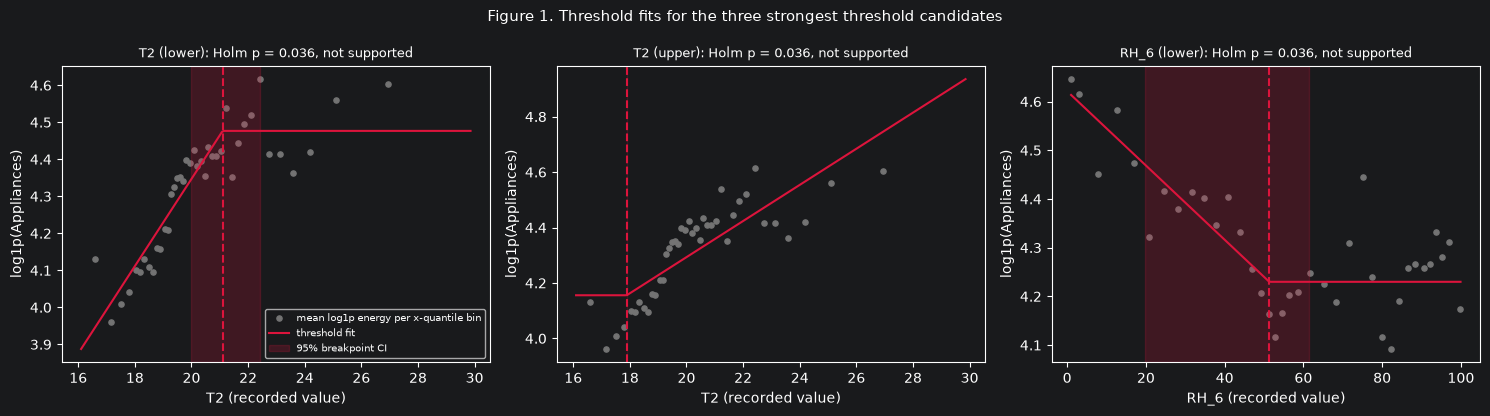

In [30]:
# ---- Figure 1: threshold plot (three smallest Holm p-values, ties broken by sup-F; supported or not is stated in each title) ----
top = Q2_MAIN.sort_values(["p_holm", "supF"], ascending=[True, False]).head(3)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (_, r) in zip(ax, top.iterrows()):
    x = abt[r.variable].to_numpy(float); y = Y_LOG
    q = pd.qcut(x, 40, duplicates="drop"); b = pd.DataFrame({"x": x, "y": y}).groupby(q, observed=True).mean()
    a.scatter(b.x, b.y, s=14, color="0.45", label="mean log1p energy per x-quantile bin")
    xg = np.linspace(x.min(), x.max(), 200); xs = (xg - r.mu) / r.sd; ts = (r.tau_hat - r.mu) / r.sd
    h = np.maximum(0, xs - ts) if r.direction == "upper" else np.maximum(0, ts - xs)
    a.plot(xg, r.a + r.b2 * h, color="crimson", label="threshold fit")
    a.axvspan(r.tau_lo, r.tau_hi, alpha=.2, color="crimson", label="95% breakpoint CI"); a.axvline(r.tau_hat, color="crimson", ls="--")
    a.set_title(f"{r.variable} ({r.direction}): Holm p = {r.p_holm:.3f}, {'supported' if r.supported_10 else 'not supported'}", fontsize=9)
    a.set_xlabel(f"{r.variable} (recorded value)"); a.set_ylabel("log1p(Appliances)")
ax[0].legend(fontsize=7); fig.suptitle("Figure 1. Threshold fits for the three strongest threshold candidates", fontsize=11)
plt.tight_layout(); fig.savefig(OUT / "fig1_thresholds.png", dpi=200); plt.show()

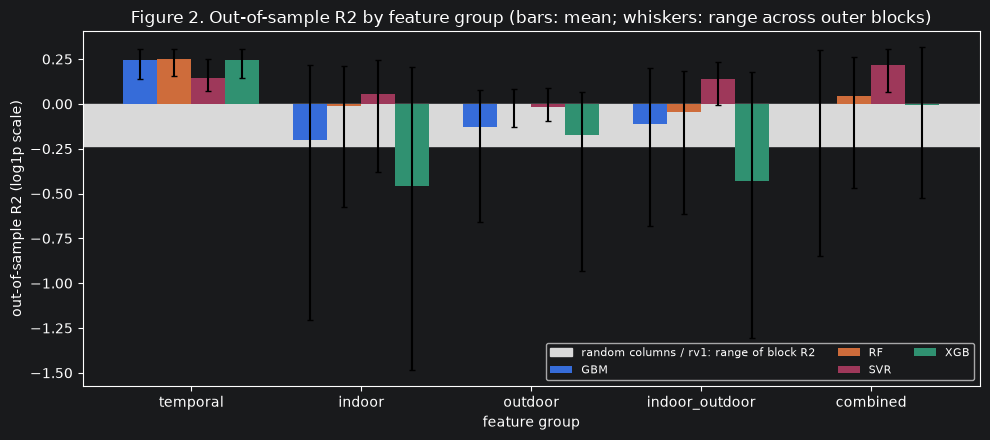

In [31]:
# ---- Figure 2: out-of-sample R2 by group, with range across blocks and the random-column band ----
order = [g for g in GROUPS_Q3 if g not in ("rv1", "random_20")]
models = sorted(M.model.unique()); fig, ax = plt.subplots(figsize=(10, 4.5)); w = 0.8 / len(models)
for i, m in enumerate(models):
    s = R2T[R2T.model == m].set_index("group").loc[order]
    ax.bar(np.arange(len(order)) + i * w, s.mean_r2, w, label=m, yerr=[s.mean_r2 - s.min_r2, s.max_r2 - s.mean_r2], capsize=2, zorder=3)
nul = M[M.group.isin(["random_20", "rv1"])].r2
ax.axhspan(nul.min(), nul.max(), color="0.85", zorder=0, label="random columns / rv1: range of block R2")
ax.set_xticks(np.arange(len(order)) + w * (len(models) - 1) / 2); ax.set_xticklabels(order)
ax.set_xlabel("feature group"); ax.set_ylabel("out-of-sample R2 (log1p scale)"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Figure 2. Out-of-sample R2 by feature group (bars: mean; whiskers: range across outer blocks)")
plt.tight_layout(); fig.savefig(OUT / "fig2_r2.png", dpi=200); plt.show()

In [32]:
(OUT / "caption_drafts.md").write_text(
    "**Figure 1.** Threshold regression of log1p(Appliances) on the three sensors with the smallest Holm-adjusted p-values (ties broken by the sup-F statistic). "
    "Points are mean log energy within 40 quantile bins; the red line is the fitted threshold model; the shaded band is the 95% block-bootstrap CI of the breakpoint. "
    "The panel title states whether the threshold met all five support criteria. Associations only.\n\n"
    "**Figure 2.** Out-of-sample R2 (log1p scale) for each feature group and model on identical contiguous time blocks with a 1-day buffer. "
    "Bars are means across blocks, whiskers the range; the grey band spans the R2 reached by rv1 and the 20 random columns. "
    "Values express incremental predictive value, not causal or uniquely attributable variance.\n")
print("saved: caption_drafts.md, fig1_thresholds.png, fig2_r2.png")

saved: caption_drafts.md, fig1_thresholds.png, fig2_r2.png


## 7 · Run Summary

In [33]:
FILES = [OUT / f for f in ("threshold_table.csv", "r2_table.csv", "q1_bands.csv", "q3_fold_results.csv", "q3_negative_control.csv",
                           "fig1_thresholds.png", "fig2_r2.png", "caption_drafts.md")]
check("all report files written", all(f.is_file() for f in FILES))
check("identical outer blocks for every group and model", Q3.groupby(["run", "group", "model"]).fold.apply(lambda s: sorted(s) == list(range(N_OUTER))).all())
check("Holm applied across all main tests", Q2_MAIN.shape[0] == 2 * len(Q_VARS))
print(f"Total runtime: {(time.perf_counter() - T0) / 60:.1f} min")
print(f"Supported thresholds (5% / 10% / 20% floor): {[int(Q2_MAIN[f'supported_{f}'].sum()) for f in FLOORS]}")
print("Files written:", *[str(f) for f in FILES], sep="\n  ")
assert all(CHECKS.values()), [k for k, v in CHECKS.items() if not v]
print(f"\n{len(CHECKS)} checks passed: " + "; ".join(CHECKS))
print("ALL CHECKS PASSED")

Total runtime: 27.8 min
Supported thresholds (5% / 10% / 20% floor): [0, 0, 0]
Files written:
  report_assets\threshold_table.csv
  report_assets\r2_table.csv
  report_assets\q1_bands.csv
  report_assets\q3_fold_results.csv
  report_assets\q3_negative_control.csv
  report_assets\fig1_thresholds.png
  report_assets\fig2_r2.png
  report_assets\caption_drafts.md

6 checks passed: ABT loaded; Q variables present; Q3 pipeline sanity: temporal beats the noise controls for every model; all report files written; identical outer blocks for every group and model; Holm applied across all main tests
ALL CHECKS PASSED


---
### Handoff to the report

| Report section | Source file |
|---|---|
| Findings summary, limitations | written by hand from the tables below |
| Two plots with captions | `fig1_thresholds.png`, `fig2_r2.png`, `caption_drafts.md` |
| Threshold table with crossing frequencies | `threshold_table.csv` |
| Temporal vs environmental R² table | `r2_table.csv` (plus `q3_negative_control.csv`) |
| Literature / RRL with DOI | Notebook 3 |

### References

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). https://doi.org/10.1145/2939672.2939785

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.

Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241. https://doi.org/10.1214/aos/1176347265

Muggeo, V. M. R. (2003). Estimating regression models with unknown break-points. *Statistics in Medicine, 22*(19), 3055–3071. https://doi.org/10.1002/sim.1545

O'Brien, R. M. (2007). A caution regarding rules of thumb for variance inflation factors. *Quality & Quantity, 41*(5), 673–690. https://doi.org/10.1007/s11135-006-9018-6

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing, 14*(3), 199–222. https://doi.org/10.1023/B:STCO.0000035301.49549.88